In [1]:
import sys
print(sys.executable)
print(sys.version)
import lzma
print("LZMA works")

d:\ml final project\.venv-test314\Scripts\python.exe
3.14.7 (main, Sep  1 2026, 14:17:30) [MSC v.1944 64 bit (AMD64)]
LZMA works


In [2]:
import os
import random
import shutil
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm
import cv2

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.models as models
from torchvision.models import ResNet34_Weights

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = False
torch.backends.cudnn.benchmark = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU ONLY - install the CUDA build of PyTorch")
DATA_DIR = "archive (3)"
IMG_SIZE = 128
NUM_EPOCHS = 25
BATCH_SIZE = 64
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

d:\ml final project\.venv-test314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda | NVIDIA GeForce RTX 5060 Laptop GPU


In [3]:
train_df = pd.read_csv(os.path.join(DATA_DIR, "Train.csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "Test.csv"))

## EDA


C:\Users\yassi\AppData\Local\Temp\ipykernel_10964\3820231164.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=train_df, x="ClassId", palette="viridis")


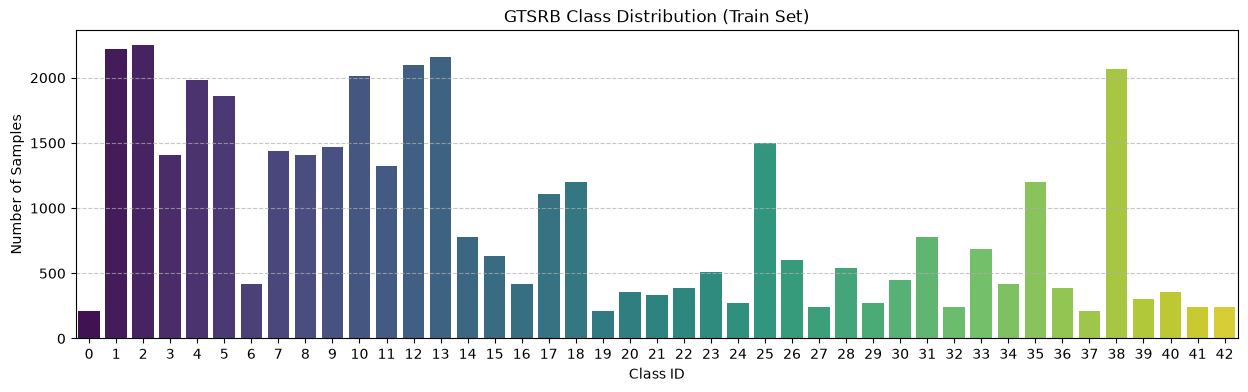

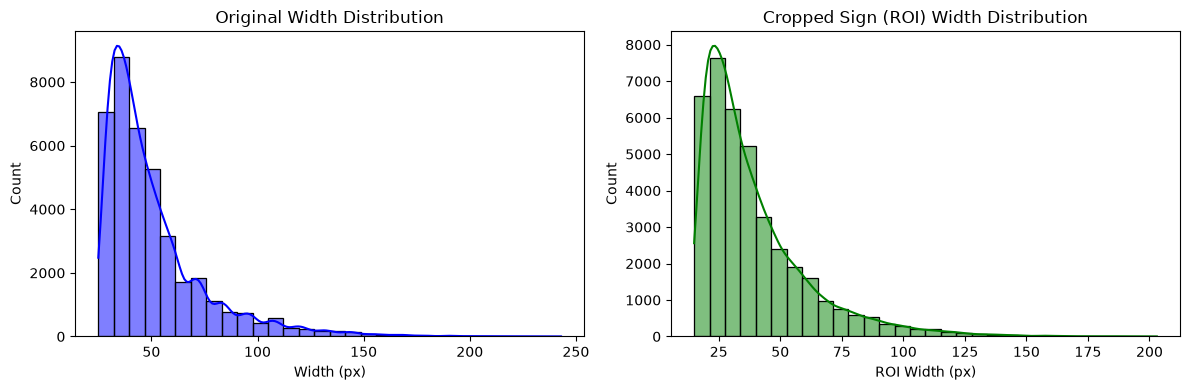

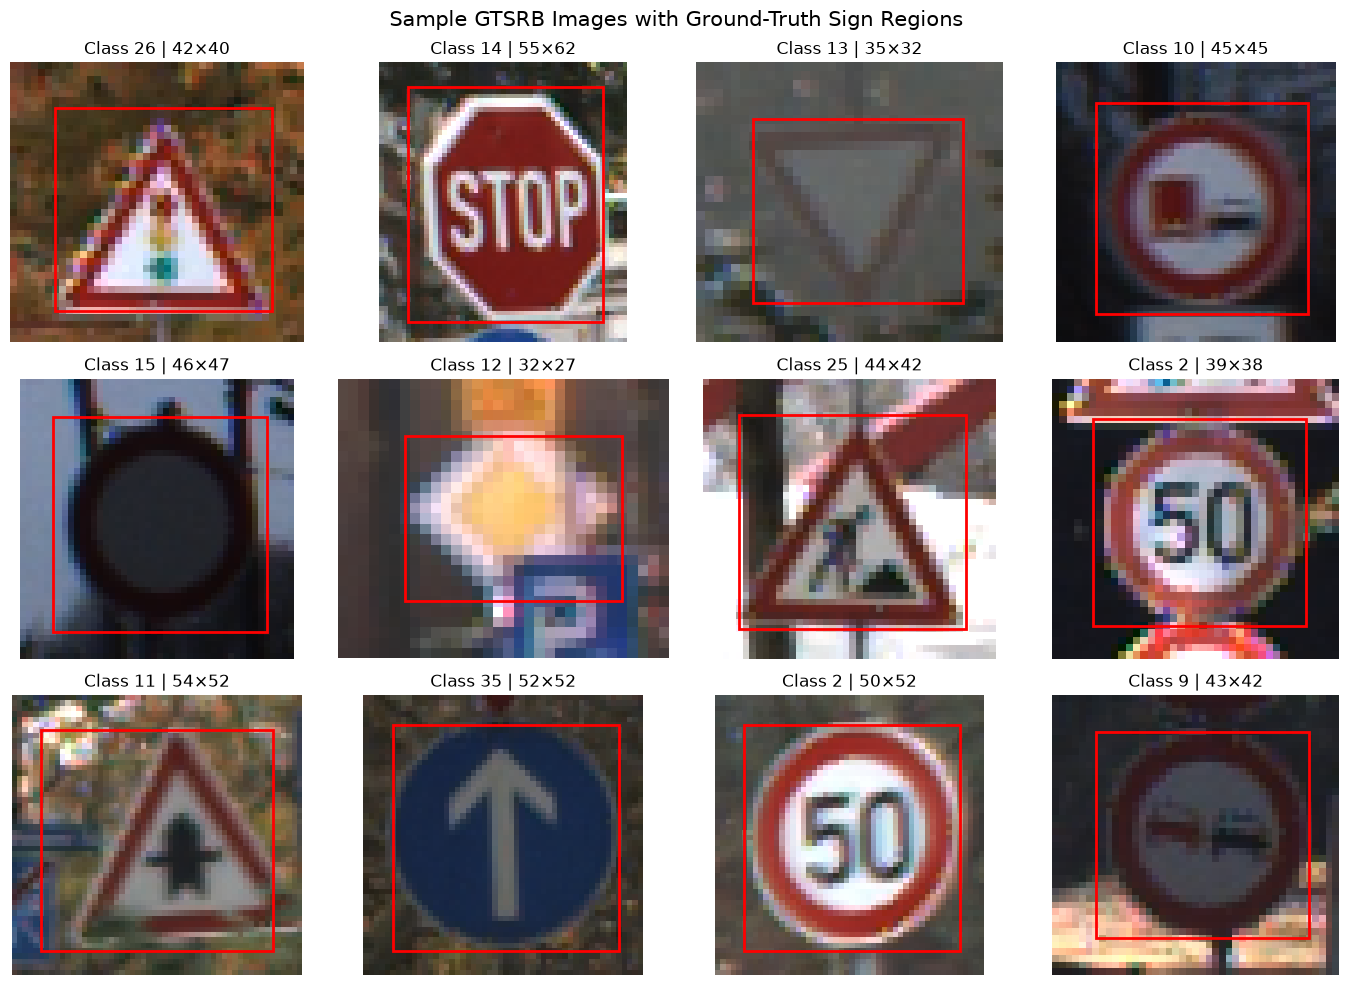

In [ ]:
plt.figure(figsize=(15, 4))
sns.countplot(data=train_df, x="ClassId", palette="viridis")
plt.title("GTSRB Class Distribution (Train Set)")
plt.xlabel("Class ID")
plt.ylabel("Number of Samples")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

train_df["Roi.W"] = train_df["Roi.X2"] - train_df["Roi.X1"]
train_df["Roi.H"] = train_df["Roi.Y2"] - train_df["Roi.Y1"]

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.histplot(train_df["Width"], color="blue", bins=30, kde=True)
plt.title("Original Width Distribution")
plt.xlabel("Width (px)")

plt.subplot(1, 2, 2)
sns.histplot(train_df["Roi.W"], color="green", bins=30, kde=True)
plt.title("Cropped Sign (ROI) Width Distribution")
plt.xlabel("ROI Width (px)")
plt.tight_layout()
plt.show()
sample_df = train_df.sample(n=min(12, len(train_df)), random_state=SEED).reset_index(drop=True)
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
axes = axes.flatten()

for ax, (_, row) in zip(axes, sample_df.iterrows()):
    image_path = os.path.join(DATA_DIR, row["Path"])
    with Image.open(image_path) as img:
        img = img.convert("RGB")
        ax.imshow(img)
        x1, y1 = int(row["Roi.X1"]), int(row["Roi.Y1"])
        x2, y2 = int(row["Roi.X2"]), int(row["Roi.Y2"])
        ax.add_patch(plt.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            fill=False, edgecolor="red", linewidth=2
        ))
    ax.set_title(f"Class {int(row['ClassId'])} | {int(row['Width'])}×{int(row['Height'])}")
    ax.axis("off")

for ax in axes[len(sample_df):]:
    ax.axis("off")

plt.suptitle("Sample GTSRB Images with Ground-Truth Sign Regions", fontsize=15)
plt.tight_layout()
plt.show()


##  Prepare CNN data

In [5]:
train_df["Track"] = train_df["Path"].str.extract(r"_(\d+)_\d+\.png")[0]
groups = train_df["ClassId"].astype(str) + "_" + train_df["Track"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.10, random_state=SEED)
tr_idx, va_idx = next(gss.split(train_df, train_df["ClassId"], groups))
train_records = train_df.iloc[tr_idx].reset_index(drop=True)
val_records = train_df.iloc[va_idx].reset_index(drop=True)
print(f"train: {len(train_records)} | val: {len(val_records)} | test: {len(test_df)}")

def preload_cropped_images(df, data_dir, target_size=(128, 128)):
    images, labels = [], []
    for _, row in df.iterrows():
        img_path = os.path.join(data_dir, row["Path"])
        with Image.open(img_path) as img:
            rgb_img = img.convert("RGB")
            crop_box = (row["Roi.X1"], row["Roi.Y1"], row["Roi.X2"], row["Roi.Y2"])
            cropped = rgb_img.crop(crop_box).resize(target_size, Image.Resampling.LANCZOS)
            images.append(np.array(cropped, dtype=np.uint8))
            labels.append(int(row["ClassId"]))
    return np.array(images), np.array(labels)

X_train_raw, y_train_raw = preload_cropped_images(train_records, DATA_DIR, (IMG_SIZE, IMG_SIZE))
X_val_raw, y_val_raw = preload_cropped_images(val_records, DATA_DIR, (IMG_SIZE, IMG_SIZE))
X_test_raw, y_test_raw = preload_cropped_images(test_df, DATA_DIR, (IMG_SIZE, IMG_SIZE))

train: 35279 | val: 3930 | test: 12630


In [6]:
import math
import torch.nn.functional as F

mean_t = torch.tensor(MEAN, device=device).view(1, 3, 1, 1)
std_t = torch.tensor(STD, device=device).view(1, 3, 1, 1)

def gpu_augment(x):
    B = x.size(0)
    ang = (torch.rand(B, device=device) * 2 - 1) * math.radians(10)
    s = 0.9 + torch.rand(B, device=device) * 0.2
    tx = (torch.rand(B, device=device) * 2 - 1) * 0.2
    ty = (torch.rand(B, device=device) * 2 - 1) * 0.2
    cos, sin = torch.cos(ang) / s, torch.sin(ang) / s
    theta = torch.stack([torch.stack([cos, -sin, tx], 1),
                         torch.stack([sin,  cos, ty], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    x = F.grid_sample(x, grid, padding_mode="zeros", align_corners=False)

    b = 0.7 + torch.rand(B, 1, 1, 1, device=device) * 0.6
    c = 0.7 + torch.rand(B, 1, 1, 1, device=device) * 0.6
    x = x * b
    m = x.mean(dim=(1, 2, 3), keepdim=True)
    x = (x - m) * c + m
    return x.clamp(0, 1)

class GPULoader:
    def __init__(self, images_np, labels_np, batch_size, train=False):
        self.x = torch.from_numpy(images_np).permute(0, 3, 1, 2).contiguous().to(device)
        self.y = torch.from_numpy(labels_np).long().to(device)
        self.bs, self.train = batch_size, train

    def __len__(self):
        return math.ceil(len(self.x) / self.bs)

    def __iter__(self):
        n = len(self.x)
        idx = torch.randperm(n, device=device) if self.train else torch.arange(n, device=device)
        for i in range(0, n, self.bs):
            j = idx[i:i + self.bs]
            x = self.x[j].float() / 255.0
            if self.train:
                x = gpu_augment(x)
            x = ((x - mean_t) / std_t).contiguous(memory_format=torch.channels_last)
            yield x, self.y[j]

train_loader = GPULoader(X_train_raw, y_train_raw, BATCH_SIZE, train=True)
val_loader = GPULoader(X_val_raw, y_val_raw, BATCH_SIZE)
test_loader = GPULoader(X_test_raw, y_test_raw, BATCH_SIZE)

In [7]:
def get_model(num_classes=43):
    m = models.resnet34(weights=ResNet34_Weights.IMAGENET1K_V1)
    m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.fc.in_features, num_classes))
    return m

model = get_model(43).to(device, memory_format=torch.channels_last)
use_cuda = torch.cuda.is_available()

criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
optimizer = optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS, eta_min=1e-6)
scaler = torch.amp.GradScaler("cuda", enabled=use_cuda)

## Train the CNN


In [8]:
train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []
best_val_acc = 0.0

for epoch in range(NUM_EPOCHS):
    model.train()
    running_loss = torch.zeros((), device=device)
    correct = torch.zeros((), device=device)
    total = 0
    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1:02d}/{NUM_EPOCHS} [Train]"):
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast(device_type="cuda" if use_cuda else "cpu", enabled=use_cuda):
            outputs = model(images)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.detach() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum()
        total += labels.size(0)
    train_losses.append(running_loss.item() / total)
    train_accuracies.append(correct.item() / total)

    model.eval()
    val_loss = torch.zeros((), device=device)
    correct = torch.zeros((), device=device)
    total = 0
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc=f"Epoch {epoch+1:02d}/{NUM_EPOCHS} [Val]"):
            with torch.amp.autocast(device_type="cuda" if use_cuda else "cpu", enabled=use_cuda):
                outputs = model(images)
                loss = criterion(outputs, labels)
            val_loss += loss.detach() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum()
            total += labels.size(0)
    val_losses.append(val_loss.item() / total)
    val_accuracies.append(correct.item() / total)
    scheduler.step()

    print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS} | Train Loss: {train_losses[-1]:.4f} Acc: {train_accuracies[-1]*100:.2f}% "
          f"| Val Loss: {val_losses[-1]:.4f} Acc: {val_accuracies[-1]*100:.2f}%")

    if val_accuracies[-1] > best_val_acc:
        best_val_acc = val_accuracies[-1]
        torch.save(model.state_dict(), "best_resnet_gtsrb.pth")
        print("  --> Saved Best Model!")

Epoch 01/25 [Train]:   0%|          | 0/552 [00:00<?, ?it/s]

Epoch 01/25 [Val]: 100%|██████████| 62/62 [00:04<00:00, 14.25it/s]


Epoch 01/25 | Train Loss: 0.5602 Acc: 95.57% | Val Loss: 0.4100 Acc: 99.64%
  --> Saved Best Model!


Epoch 02/25 [Val]: 100%|██████████| 62/62 [00:00<00:00, 112.65it/s]


Epoch 02/25 | Train Loss: 0.4216 Acc: 99.35% | Val Loss: 0.4309 Acc: 98.75%


...

Epoch 23/25 | Train Loss: 0.3821 Acc: 100.00% | Val Loss: 0.3793 Acc: 99.97%


Epoch 24/25 [Val]: 100%|██████████| 62/62 [00:00<00:00, 110.31it/s]


Epoch 24/25 | Train Loss: 0.3822 Acc: 99.99% | Val Loss: 0.3794 Acc: 99.97%


Epoch 25/25 [Val]: 100%|██████████| 62/62 [00:00<00:00, 112.42it/s]

Epoch 25/25 | Train Loss: 0.3819 Acc: 100.00% | Val Loss: 0.3796 Acc: 99.95%


##  Evaluate CNN

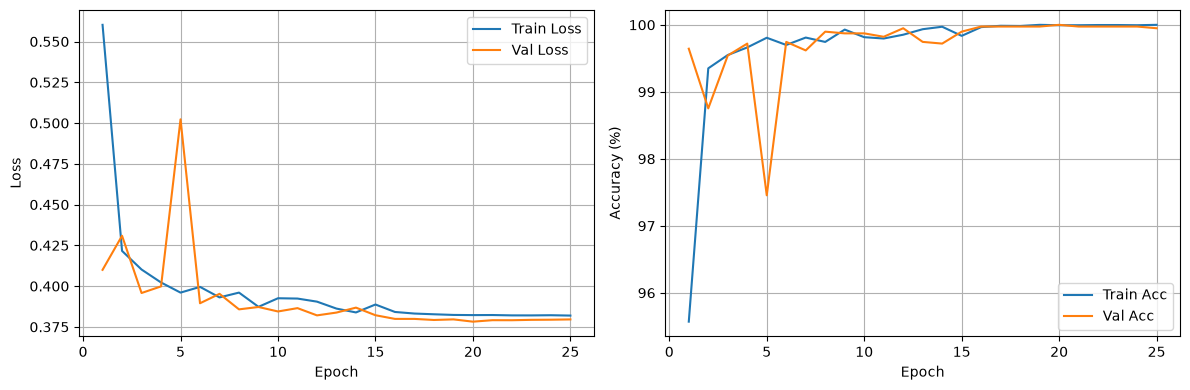


[+] FINAL TEST ACCURACY: 99.15%

              precision    recall  f1-score   support

           0     0.8219    1.0000    0.9023        60
           1     0.9972    1.0000    0.9986       720
           2     1.0000    0.9933    0.9967       750
           3     0.9955    0.9800    0.9877       450
           4     1.0000    0.9970    0.9985       660
           5     0.9530    0.9984    0.9752       630
           6     1.0000    0.8467    0.9170       150
           7     1.0000    1.0000    1.0000       450
           8     0.9934    1.0000    0.9967       450
           9     1.0000    1.0000    1.0000       480
          10     0.9985    1.0000    0.9992       660
          11     0.9976    1.0000    0.9988       420
          12     1.0000    0.9971    0.9985       690
          13     0.9986    0.9972    0.9979       720
          14     1.0000    0.9963    0.9981       270
          15     0.9953    1.0000    0.9976       210
          16     1.0000    1.0000    1.0000    

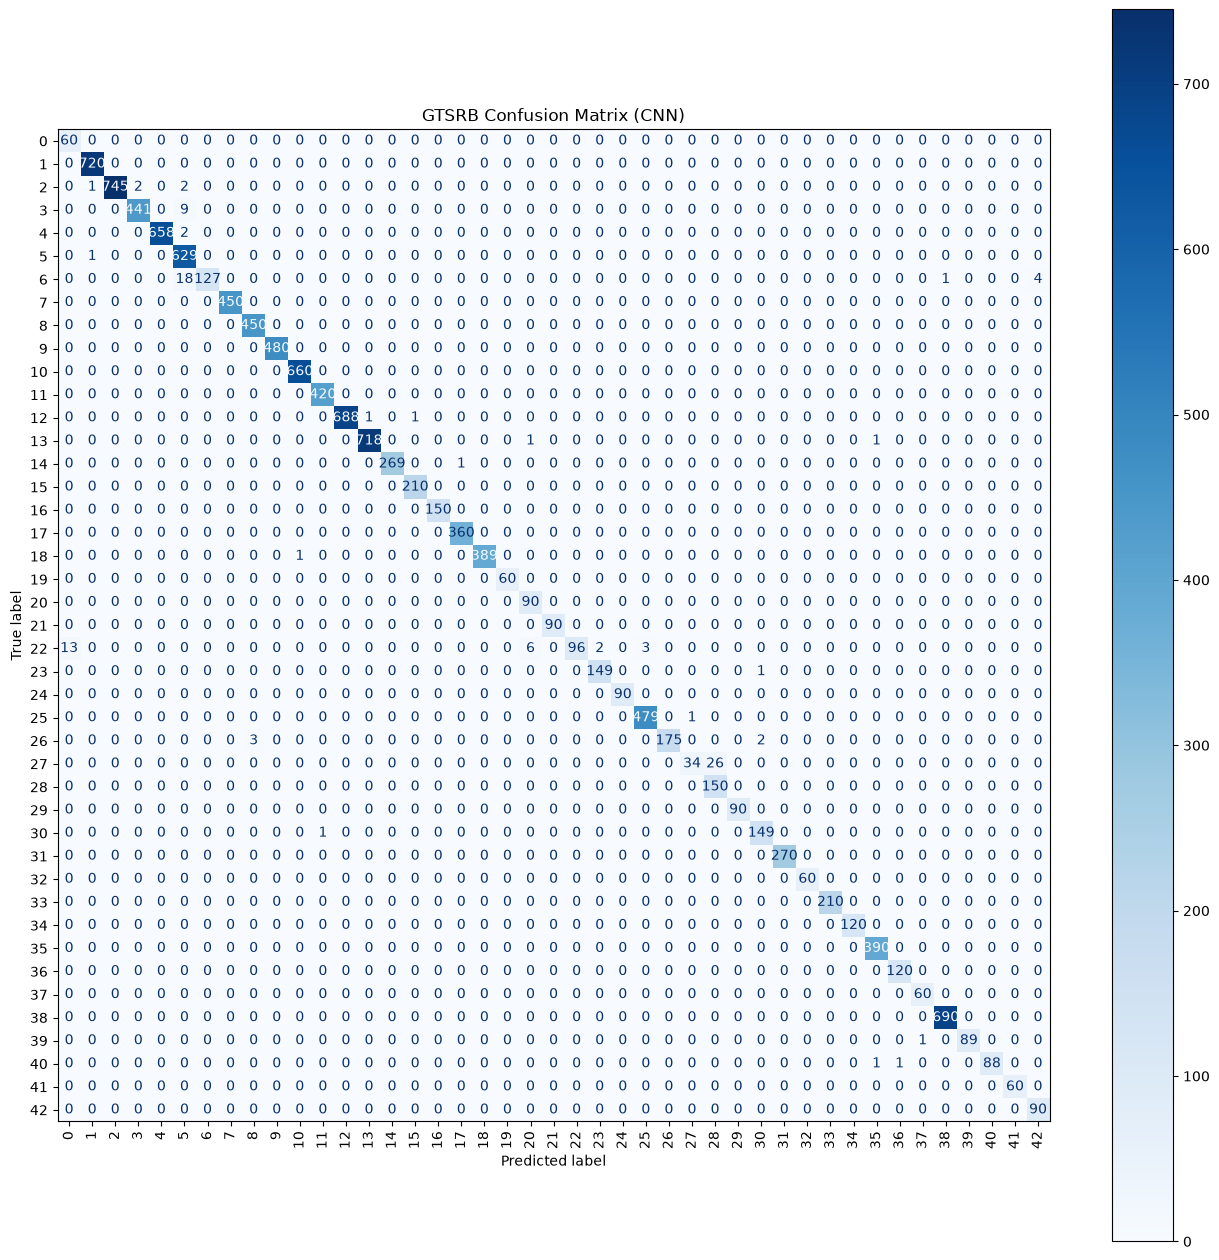

In [9]:
epochs_range = range(1, len(train_losses) + 1)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_losses, label="Train Loss")
plt.plot(epochs_range, val_losses, label="Val Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.grid(True)
plt.subplot(1, 2, 2)
plt.plot(epochs_range, np.array(train_accuracies) * 100, label="Train Acc")
plt.plot(epochs_range, np.array(val_accuracies) * 100, label="Val Acc")
plt.xlabel("Epoch"); plt.ylabel("Accuracy (%)"); plt.legend(); plt.grid(True)
plt.tight_layout()
plt.show()

model.load_state_dict(torch.load("best_resnet_gtsrb.pth", map_location=device, weights_only=True))
model.eval()

all_predictions, all_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        with torch.amp.autocast(device_type="cuda" if use_cuda else "cpu", enabled=use_cuda):
            outputs = model(images)
        all_predictions.extend(outputs.argmax(1).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)
print(f"\n[+] FINAL TEST ACCURACY: {(all_predictions == all_labels).mean() * 100:.2f}%\n")
print(classification_report(all_labels, all_predictions, digits=4))

fig, ax = plt.subplots(figsize=(16, 16))
cm = confusion_matrix(all_labels, all_predictions)
ConfusionMatrixDisplay(confusion_matrix=cm).plot(cmap="Blues", xticks_rotation="vertical", ax=ax)
plt.title("GTSRB Confusion Matrix (CNN)")
plt.show()

In [10]:
YOLO_DIR = os.path.abspath("yolo_gtsrb")

def to_yolo(df, split):
    img_dir, lbl_dir = f"{YOLO_DIR}/images/{split}", f"{YOLO_DIR}/labels/{split}"
    os.makedirs(img_dir, exist_ok=True)
    os.makedirs(lbl_dir, exist_ok=True)
    for _, r in tqdm(df.iterrows(), total=len(df), desc=split):
        name = r["Path"].replace("/", "_").replace("\\", "_")
        shutil.copy(os.path.join(DATA_DIR, r["Path"]), f"{img_dir}/{name}")
        w, h = r["Width"], r["Height"]
        xc = (r["Roi.X1"] + r["Roi.X2"]) / 2 / w
        yc = (r["Roi.Y1"] + r["Roi.Y2"]) / 2 / h
        bw = (r["Roi.X2"] - r["Roi.X1"]) / w
        bh = (r["Roi.Y2"] - r["Roi.Y1"]) / h
        with open(f"{lbl_dir}/{name.rsplit('.', 1)[0]}.txt", "w") as f:
            f.write(f"{int(r['ClassId'])} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}\n")

to_yolo(train_records, "train")
to_yolo(val_records, "val")
to_yolo(test_df, "test")

with open(f"{YOLO_DIR}/data.yaml", "w") as f:
    yaml.dump({"path": YOLO_DIR, "train": "images/train", "val": "images/val",
               "test": "images/test", "names": {i: str(i) for i in range(43)}}, f)

test: 100%|██████████| 12630/12630 [00:09<00:00, 1268.89it/s]


##  Train YOLO


In [11]:
from ultralytics import YOLO

yolo = YOLO("yolov8n.pt")
yolo.train(data=f"{YOLO_DIR}/data.yaml", epochs=30, imgsz=128, batch=64,
           fliplr=0.0, seed=SEED, project="yolo_runs", name="gtsrb", exist_ok=True,
           device=0 if torch.cuda.is_available() else "cpu")

best_yolo = YOLO(str(yolo.trainer.best))
metrics = best_yolo.val(data=f"{YOLO_DIR}/data.yaml", split="test", imgsz=128,
                        device=0 if torch.cuda.is_available() else "cpu")
print(f"YOLO test mAP@0.5: {metrics.box.map50:.4f} | mAP@0.5:0.95: {metrics.box.map:.4f}")

New https://pypi.org/project/ultralytics/8.4.177 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.175  Python-3.14.7 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8151MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=d:\ml final project\yolo_gtsrb/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=128, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=

##  Visualizations


Ground Truth      : [Class 3] Speed 60
CNN Prediction    : [Class 3] Speed 60 (94.98%)
CNN Match         : CORRECT
YOLO Boxes Found  : 1


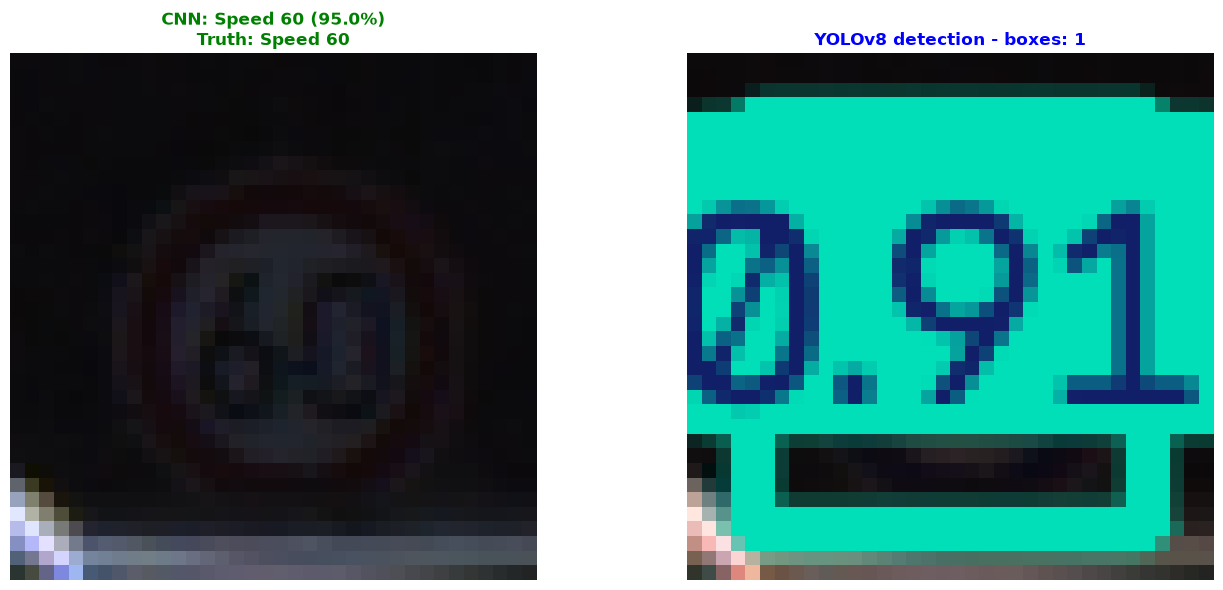

In [ ]:
class_names = [
 "Speed 20","Speed 30","Speed 50","Speed 60","Speed 70","Speed 80","End speed 80","Speed 100",
 "Speed 120","No passing","No passing >3.5t","Right-of-way at next intersection","Priority road",
 "Yield","Stop","No vehicles","No vehicles >3.5t","No entry","General caution",
 "Dangerous curve left","Dangerous curve right","Double curve","Bumpy road","Slippery road",
 "Road narrows right","Road work","Traffic signals","Pedestrians","Children crossing",
 "Bicycles crossing","Beware ice/snow","Wild animals crossing","End all limits","Turn right ahead",
 "Turn left ahead","Ahead only","Go straight or right","Go straight or left","Keep right",
 "Keep left","Roundabout mandatory","End no passing","End no passing >3.5t"]

TEST_IMAGE_PATH = os.path.join(DATA_DIR, "Test", "00090.png")
image_filename = os.path.basename(TEST_IMAGE_PATH)
matched_row = test_df[test_df["Path"].str.endswith(image_filename)]
r = matched_row.iloc[0]
true_class_id = int(r["ClassId"])

raw_img = Image.open(TEST_IMAGE_PATH).convert("RGB")
img_np = np.array(raw_img)

cnn_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])
cnn_crop = raw_img.crop((int(r["Roi.X1"]), int(r["Roi.Y1"]), int(r["Roi.X2"]), int(r["Roi.Y2"])))
tensor_img = cnn_transforms(cnn_crop).unsqueeze(0).to(device)
model.eval()
with torch.no_grad():
    probs = torch.softmax(model(tensor_img), dim=1)
    confidence, predicted_class = torch.max(probs, dim=1)
pred_class_id = predicted_class.item()
conf_score = confidence.item() * 100
is_correct = pred_class_id == true_class_id

yolo_results = best_yolo(img_np, conf=0.25, device=device, verbose=False)
num_boxes = len(yolo_results[0].boxes)
yolo_annotated_rgb = cv2.cvtColor(yolo_results[0].plot(), cv2.COLOR_BGR2RGB)

print("=" * 60)
print(f"Ground Truth      : [Class {true_class_id}] {class_names[true_class_id]}")
print(f"CNN Prediction    : [Class {pred_class_id}] {class_names[pred_class_id]} ({conf_score:.2f}%)")
print(f"CNN Match         : {'CORRECT' if is_correct else 'WRONG'}")
print(f"YOLO Boxes Found  : {num_boxes}")
print("=" * 60)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(raw_img)
axes[0].set_title(f"CNN: {class_names[pred_class_id]} ({conf_score:.1f}%)\nTruth: {class_names[true_class_id]}",
                  color="green" if is_correct else "red", fontweight="bold")
axes[0].axis("off")
axes[1].imshow(yolo_annotated_rgb)
axes[1].set_title(f"YOLOv8 detection - boxes: {num_boxes}", color="blue", fontweight="bold")
axes[1].axis("off")
plt.tight_layout()
plt.show()